# Desarrollo 03: lago Owasco, la segunda mejora del algoritmo

El notebook 02 dejo la v2: para cada fila candidata se suman dos pistas, la **separacion** (arriba la mira se parece a una foto seca y abajo no) y el **espejo**, con **los mismos valores en todas las camaras**. Aqui se sigue la regla de esta carpeta: **se copia ese notebook cambiando solo la configuracion, se mira que falla, y se cambia solo lo que el fallo obliga**, sin empeorar los ejemplos anteriores.

**Resultado.** La v2 sin cambios, con la regla enderezada con lados paralelos como en las pruebas anteriores, da en las 6 secciones de Owasco **10.91 cm de error absoluto medio y 48.2 % en +-5 cm** (166 fotos comparadas): la camara ve la regla de lado y la regla sale torcida. Solo con la regla en perspectiva (cambio 1) baja a **5.41 cm** (180 fotos), y la v3, con los tres cambios, da **2.92 cm y 86.1 % en +-5 cm** (209 fotos); despues del cambio de encuadre ya hay lectura (1.31 cm). **Con los mismos valores, China mejora** (secciones 2.11 cm frente a 4.12; serie completa 0.99 cm frente a 2.91) **y Meguro queda casi igual** (0.98 cm frente a 0.87, por un corrimiento fijo frente al nivel oficial). **Sin resolver:** con el agua bajo la placa la lectura sigue cayendo sobre ella. No es una prueba a ciegas (parte 7).

| Parte | |
|---|---|
| 1. Copia del notebook 02 | mismo codigo, solo cambia la configuracion. Tabla de valores China / Owasco |
| 2. Datos iniciales | la v2, sin cambios, por seccion frente a la referencia |
| 3. Problemas | la regla torcida, cada pista por separado, fotos, y los problemas que sirven para otros sitios |
| 4. Cambios al codigo | la regla en perspectiva, la zona de la separacion y varios encuadres; cada cambio con su diff |
| 5. Resultados en Owasco | v2, v2 con solo la regla en perspectiva, y v3, por seccion frente a la referencia; video de la v3 |
| 6. Comprobacion en China y Meguro | el mismo codigo v3, con los mismos valores |
| 7. Limitaciones | que queda sin resolver |

**De donde sale cada numero.** En Owasco, todo se calcula sobre **6 secciones** de la serie (226 fotos). En China, sobre sus 5 secciones y su serie completa; en Meguro, sobre sus 53 fotos.

# 1. Copia del notebook 02

## 1.1 Preparacion y datos

**Datos.** Camara de la red HIVIS del Servicio Geologico de Estados Unidos (USGS), sobre la mira de la estacion 04235396, lago Owasco, Nueva York: 4790 fotos de 1520 x 2688 px, aproximadamente una por hora de dia, del 23-sep-2025 al 19-oct-2026. La mira son dos placas en pies atornilladas a un poste: la de arriba de 16.9 a 13.6 ft y la de abajo de 13.3 a 10.7 ft. El agua se mueve en la de abajo. La referencia es la cota oficial del lago, cada 15 min, y **solo se abre en la parte 2**.

**Las secciones.** Son bloques continuos de la serie, sin quitar ninguna foto de dentro. **Se eligieron solo mirando las imagenes**, en hojas con una foto de cada dia, con la regla "el primer bloque de tres dias en que aparece esa condicion":

| Seccion | Bloque | Como se eligio |
|---|---|---|
| agua transparente | 24 a 26-sep-2025 | el agua cubre el pie de la placa y se ve la placa debajo: los primeros dias de la serie |
| sin agua, con nieve | 22 a 24-ene-2026 | la primera nieve que dura varios dias, con el agua bajo la placa |
| agua entrando en la placa | 8 a 10-mar-2026 | el primer regreso del agua a la placa tras el invierno |
| agua turbia | 1 a 3-abr-2026 | se eligio como "agua turbia"; mirando de nuevo las fotos, la lente esta limpia y el agua esta turbia |
| agua alta, placa verde | 13 a 15-may-2026 | los primeros dias con la placa cubierta de algas y el agua arriba |
| cambio de encuadre | 12 a 14-sep-2026 | el primer bloque que cruza un cambio de encuadre entre dos fotos nitidas |

**Lo que se sabia antes de elegir.** Esta camara ya se conocia, incluidos resultados previos, asi que la prueba no es del todo a ciegas (parte 2). Para no elegir por resultado se uso la regla "el primero", y las secciones no se cambiaron despues de abrir la referencia.

In [1]:
import ast
import difflib
import json
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

sys.path.insert(0, os.path.join("..", "..", "herramientas"))
import escritor_video                     # escribe H.264 por una tuberia a ffmpeg (cv2.VideoWriter no sirve aqui)

plt.rcParams.update({"figure.dpi": 90, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.labelcolor": "#52514e"})

# Colores de las figuras: rojo = linea de agua, azul = ventanas, amarillo = marcas y lectura a ojo
ROJO, AZUL, NARANJA, AMARILLO = "#e34948", "#2a78d6", "#eb6834", "#eda100"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

DATOS = os.path.join("..", "..", "02_usgs_hivis_owasco", "datos")
CARPETA_FOTOS = os.path.join(DATOS, "fotos")
CSV_REFERENCIA = os.path.join(DATOS, "referencia_usgs.csv")     # solo se abre en la parte 2
SALIDAS = "salidas"
os.makedirs(SALIDAS, exist_ok=True)

TEXTO_NIVEL = (0, 0, 0, 0)                # x0, y0, x1, y1: en este ejemplo no hay nivel impreso que tapar
PIE = 30.48                               # la mira esta en pies; por dentro todo va en cm de mira


def leer(archivo):
    img = cv2.imread(os.path.join(CARPETA_FOTOS, archivo))
    x0, y0, x1, y1 = TEXTO_NIVEL
    img[y0:y1, x0:x1] = 0
    return img


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def gris(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def hora_de(archivo):
    # ..._2025-12-23T17-00-06Z.jpg -> 2025-12-23 17:00:06 (UTC)
    return datetime.strptime(os.path.basename(archivo).split("___")[1][:19], "%Y-%m-%dT%H-%M-%S")


fotos = sorted(f for f in os.listdir(CARPETA_FOTOS) if f.endswith(".jpg"))
print("%d fotos, de %s a %s (UTC)" % (len(fotos), hora_de(fotos[0]), hora_de(fotos[-1])))

# >>> AJUSTABLE <<< las secciones: bloques continuos, elegidos solo con la imagen
SECCIONES = {"agua transparente": ("2025-09-24 00:00", "2025-09-26 23:59"),
             "sin agua, con nieve": ("2026-01-22 00:00", "2026-01-24 23:59"),
             "agua entrando en la placa": ("2026-03-08 00:00", "2026-03-10 23:59"),
             "agua turbia": ("2026-04-01 00:00", "2026-04-03 23:59"),
             "agua alta, placa verde": ("2026-05-13 00:00", "2026-05-15 23:59"),
             "cambio de encuadre": ("2026-09-12 00:00", "2026-09-14 23:59")}


def seccion_de(archivo):
    h = hora_de(archivo)
    for nombre, (t0, t1) in SECCIONES.items():
        if pd.Timestamp(t0) <= h <= pd.Timestamp(t1):
            return nombre
    return None


fotos_s = [a for a in fotos if seccion_de(a) is not None]
print("En las secciones: %d fotos" % len(fotos_s), {s: sum(seccion_de(a) == s for a in fotos_s) for s in SECCIONES})

4790 fotos, de 2025-09-23 20:00:36 a 2026-10-19 17:00:07 (UTC)


En las secciones: 226 fotos {'agua transparente': 24, 'sin agua, con nieve': 35, 'agua entrando en la placa': 40, 'agua turbia': 45, 'agua alta, placa verde': 49, 'cambio de encuadre': 33}


## 1.2 Una foto

Dos placas en un poste de madera, vistas con gran angular desde arriba y de lado. El agua es transparente: bajo la linea de agua se sigue viendo la placa, algo mas oscura y verdosa. No hay reflejo de la mira.

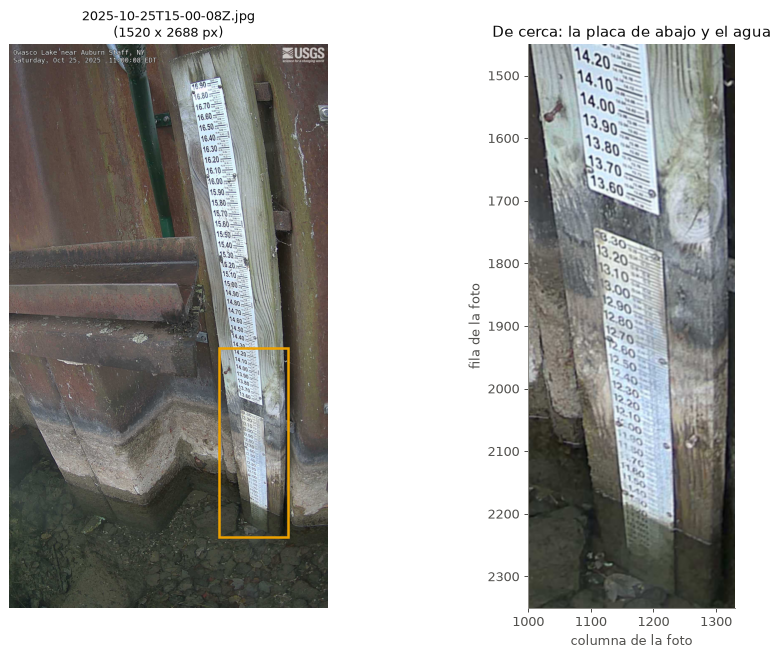

In [2]:
FOTO = "NY_Owasco_Lake_near_Auburn_Staff___2025-10-25T15-00-08Z.jpg"     # la foto con la que se explica el metodo
img = leer(FOTO)

fig, ax = plt.subplots(1, 2, figsize=(11, 7.4), gridspec_kw={"width_ratios": [1, 1.1]})
ax[0].imshow(rgb(img)); ax[0].axis("off")
ax[0].set_title("%s\n(%d x %d px)" % (FOTO.split("___")[1], img.shape[1], img.shape[0]), color=TINTA, fontsize=10)
ax[0].add_patch(Rectangle((1000, 1450), 330, 900, fill=False, ec=AMARILLO, lw=2))
ax[1].imshow(rgb(img[1450:2350, 1000:1330]), extent=[1000, 1330, 2350, 1450], interpolation="bicubic")
ax[1].set_title("De cerca: la placa de abajo y el agua", color=TINTA)
ax[1].set_xlabel("columna de la foto"); ax[1].set_ylabel("fila de la foto")
plt.tight_layout()

## 1.3 Configuracion: cuatro puntos y dos niveles

Igual que en los notebooks anteriores: a mano, una vez, sobre la foto de agua mas baja. Son los bordes de la placa y dos marcas conocidas, 14.0 y 11.0 ft. El codigo es el mismo: toma cada marca en una fila y los bordes en esa misma fila.

**Estos valores a mano ya existian** y se hicieron conociendo la referencia de esta camara, cosa que se declara en la parte 2. Aqui se comprueban sobre la foto, y las marcas de control de 1.5 dicen si son buenos.

Esquinas: sup_izq (1080.6, 1562.0), sup_der (1202.7, 1562.0), inf_der (1230.9, 2230.0), inf_izq (1151.9, 2230.0)


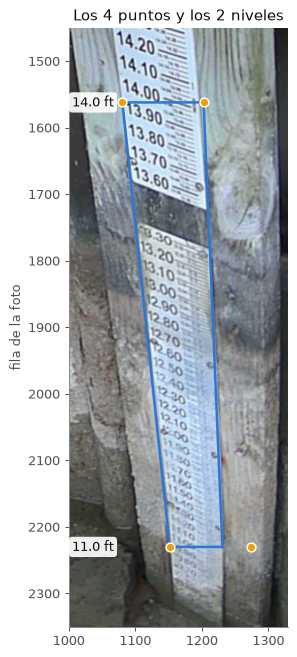

In [3]:
# >>> AJUSTABLE <<< (x, fila) de cada borde de la placa, leidos a ojo sobre ampliaciones de la foto de agua mas baja
BORDE_IZQ = [(1106, 1800), (1154, 2250)]
BORDE_DER = [(1214, 1830), (1233, 2280)]

# >>> AJUSTABLE <<< dos niveles conocidos (cm de mira) y la fila donde estan, leidos a ojo
NIVEL_SUP, FILA_SUP = 14.0 * PIE, 1562.0        # marca de 14.0 ft
NIVEL_INF, FILA_INF = 11.0 * PIE, 2230.0        # marca de 11.0 ft


def recta_por(puntos):
    (xa, ya), (xb, yb) = puntos
    return lambda y: xa + (np.asarray(y, float) - ya) * (xb - xa) / (yb - ya)


x_izq, x_der = recta_por(BORDE_IZQ), recta_por(BORDE_DER)
SUP_IZQ, SUP_DER = (float(x_izq(FILA_SUP)), FILA_SUP), (float(x_der(FILA_SUP)), FILA_SUP)
INF_DER, INF_IZQ = (float(x_der(FILA_INF)), FILA_INF), (float(x_izq(FILA_INF)), FILA_INF)
print("Esquinas: sup_izq (%.1f, %.1f), sup_der (%.1f, %.1f), inf_der (%.1f, %.1f), inf_izq (%.1f, %.1f)"
      % (*SUP_IZQ, *SUP_DER, *INF_DER, *INF_IZQ))

ref = leer("NY_Owasco_Lake_near_Auburn_Staff___2025-12-23T17-00-06Z.jpg")       # la foto de agua mas baja: toda la placa en seco
fig, a0 = plt.subplots(figsize=(5.4, 7.4))
a0.imshow(rgb(ref[1450:2350, 1000:1330]), extent=[1000, 1330, 2350, 1450], interpolation="bicubic")
a0.add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
for (x, y), texto in [(SUP_IZQ, "14.0 ft"), (INF_IZQ, "11.0 ft")]:
    a0.plot([x, x + (SUP_DER[0] - SUP_IZQ[0])], [y, y], "o", ms=7, mfc=AMARILLO, mec="white", mew=1.2)
    a0.text(1005, y, texto, color=TINTA, va="center", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.92))
a0.set_title("Los 4 puntos y los 2 niveles", color=TINTA); a0.set_ylabel("fila de la foto")
plt.tight_layout()

## 1.4 El tablero enderezado

`Tablero` es la clase del notebook 02, sin cambiar nada. Aqui 6 filas son 1 cm.

Tablero de 90 columnas x 668 filas


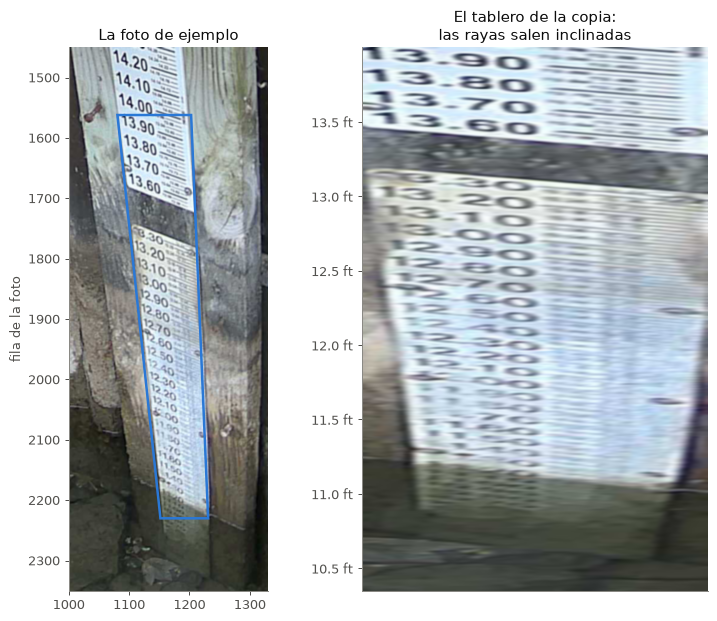

In [4]:
class Tablero:
    # 4 puntos + 2 niveles -> tablero enderezado con lados paralelos: cada fila es un nivel fijo
    def __init__(self, sup_izq, sup_der, inf_der, inf_izq, nivel_sup, nivel_inf, px_por_cm, ancho_px, extra_cm):
        self.nivel_sup, self.px_por_cm = float(nivel_sup), float(px_por_cm)
        alto = (nivel_sup - nivel_inf) * px_por_cm
        src = np.float64([sup_izq, sup_der, inf_der, inf_izq])
        dst = np.float64([[0, 0], [ancho_px, 0], [ancho_px, alto], [0, alto]])
        A = np.hstack([src, np.ones((4, 1))])
        self.M = np.array([np.linalg.lstsq(A, dst[:, i], rcond=None)[0] for i in (0, 1)])   # afin por minimos cuadrados
        self.M_inv = cv2.invertAffineTransform(self.M)
        self.tam = (int(ancho_px), int(alto + extra_cm * px_por_cm))

    def enderezar(self, img):
        return cv2.warpAffine(img, self.M, self.tam, flags=cv2.INTER_LINEAR)

    def fila_de(self, nivel):
        return (self.nivel_sup - nivel) * self.px_por_cm

    def nivel_de(self, fila):
        return self.nivel_sup - fila / self.px_por_cm

    def a_tablero(self, x, y):
        return self.M @ np.array([x, y, 1.0])       # punto de la foto -> (columna, fila) del tablero

    def a_foto(self, col, fila):
        return self.M_inv @ np.array([col, fila, 1.0])   # punto del tablero -> (x, y) de la foto


PX_POR_CM = 6.0        # >>> AJUSTABLE <<< filas del tablero por cm (la escala de la camara va de ~4.6 a ~11.5 px/cm)
ANCHO = 90             # >>> AJUSTABLE <<< columnas del tablero (la placa mide de 80 a 125 px de ancho)
EXTRA_CM = 20.0        # >>> AJUSTABLE <<< cm por debajo del nivel inferior, para que entre lo que hay bajo la placa

T = Tablero(SUP_IZQ, SUP_DER, INF_DER, INF_IZQ, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
tablero = T.enderezar(img)
alto_total = T.tam[1]
niveles = np.arange(13.5, 10.4, -0.5)

fig, ax = plt.subplots(1, 2, figsize=(8.4, 7))
ax[0].imshow(rgb(img[1450:2350, 1000:1330]), extent=[1000, 1330, 2350, 1450], interpolation="bicubic")
ax[0].add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
ax[0].set_title("La foto de ejemplo", color=TINTA); ax[0].set_ylabel("fila de la foto")
ax[1].imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
ax[1].set_yticks([T.fila_de(c * PIE) for c in niveles]); ax[1].set_yticklabels(["%.1f ft" % c for c in niveles])
ax[1].set_xticks([]); ax[1].set_title("El tablero de la copia:\nlas rayas salen inclinadas", color=TINTA)
plt.tight_layout()
print("Tablero de %d columnas x %d filas" % T.tam)

## 1.5 Marcas de control

Las marcas que no entran en el ajuste sirven para comprobar el tablero. Aqui cada marca se leyo en un punto de la foto, (x, fila), porque las rayas estan inclinadas.

In [5]:
# (x, fila) de la foto de cada marca, en ft, leidas a ojo. La de 14.0 y la de 11.0 son las del ajuste
MARCAS_CONTROL = {14.4: (1148, 1412), 13.6: (1175, 1695), 13.2: (1150, 1795), 12.5: (1165, 1967), 11.8: (1177, 2103)}

fuente = np.float32([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ])
alto_placa = (NIVEL_SUP - NIVEL_INF) * PX_POR_CM
destino = np.float32([[0, 0], [ANCHO, 0], [ANCHO, alto_placa], [0, alto_placa]])
H_libre = cv2.getPerspectiveTransform(fuente, destino)


def fila_homografia(H, x, y):
    return float(cv2.perspectiveTransform(np.float32([[[x, y]]]), H)[0, 0][1])


filas_tabla = []
for c, (x, f) in sorted(MARCAS_CONTROL.items()):
    filas_tabla.append({"marca (ft)": c, "copia: medido - real (cm)": T.nivel_de(T.a_tablero(x, f)[1]) - c * PIE})
tabla_marcas = pd.DataFrame(filas_tabla).set_index("marca (ft)").round(2)
tabla_marcas

,copia: medido - real (cm)
marca (ft),
11.8,-7.00
12.5,-9.72
13.2,-7.51
13.6,-6.01
14.4,8.34


## 1.6 El rango de medida

Con el mismo criterio de los notebooks anteriores, mirando los extremos de la serie: **maximo 13.4 ft**, porque el agua llega como mucho al tope de la placa de abajo (13.3 ft) y por encima el poste nunca se moja; **minimo 10.75 ft**, el pie de la placa.

In [6]:
NIVEL_MINIMO = 10.75 * PIE          # >>> AJUSTABLE <<< cm: el pie de la placa; por debajo no hay lectura
NIVEL_MAX_AGUA = 13.4 * PIE         # >>> AJUSTABLE <<< cm: por encima la mira esta siempre seca en esta serie (visto en las fotos)
NIVEL_MIN_BUSQUEDA = 10.65 * PIE    # >>> AJUSTABLE <<< cm: se busca algo por debajo del minimo para detectar ese caso

## 1.7 El algoritmo, tal como quedo en el notebook 02

Nada cambia: el **espejo** (notebook 01) y, del notebook 02, la **memoria de la mira seca** (separacion y espejo, cada uno llevado a 0..1 dentro de la foto y sumados con el mismo peso), el **registro** con la parte que nunca se moja y las **fotos sin lectura**. El notebook 02 exige los mismos valores en todas las camaras, y sus parametros van en cm o son relativos a la propia foto, asi que se dejan como estaban. Solo cambian las columnas, por el ancho de esta mira, y la foto seca, elegida con la misma regla: la de agua mas baja.

In [7]:
VENTANA_CM = 8.0           # >>> AJUSTABLE <<< alto de cada ventana
H = int(VENTANA_CM * PX_POR_CM)
COLUMNAS = (3, 87)         # >>> AJUSTABLE <<< columnas del tablero que se comparan (dentro de la placa)


def ncc(a, b):
    a = a - a.mean()
    b = b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-9))


def ventanas(R, y, h=H, cols=COLUMNAS):
    # arriba volteada y abajo, listas para comparar
    return R[y - h:y, cols[0]:cols[1]][::-1], R[y:y + h, cols[0]:cols[1]]


def curva_espejo(R, filas, h=H, cols=COLUMNAS):
    return np.array([ncc(*ventanas(R, y, h, cols)) for y in filas])


def espejo(R, nivel_max=NIVEL_MAX_AGUA, nivel_min=NIVEL_MIN_BUSQUEDA, h=H):
    # devuelve la fila del tablero con mas parecido en espejo, su parecido, y la curva entera
    filas = np.arange(max(int(T.fila_de(nivel_max)), h), min(int(T.fila_de(nivel_min)), R.shape[0] - h) + 1)
    s = curva_espejo(R, filas, h)
    k = int(np.argmax(s))
    return int(filas[k]), float(s[k]), filas, s


FOTO_SECA = "NY_Owasco_Lake_near_Auburn_Staff___2025-12-23T17-00-06Z.jpg"   # >>> AJUSTABLE <<< [v2] la foto de agua mas baja de la camara
BANDA_CM = 2.0            # >>> AJUSTABLE <<< [v2] alto de la banda que se compara con la mira seca
MARGEN_REGISTRO_CM = 2.5  # >>> AJUSTABLE <<< [v2] cuanto se puede mover la mira entre fotos
PARECIDO_SECO_MIN = 0.75     # >>> AJUSTABLE <<< [v2] por debajo, la parte que nunca se moja no se reconoce: foto sin lectura


def memorizar():
    # [v2] guarda la mira seca y la parte que nunca se moja: por encima del maximo del rango
    global SECA, PATRON, Z0, Z1, MARGEN
    SECA = None if FOTO_SECA is None else T.enderezar(gris(leer(FOTO_SECA)))
    MARGEN = int(MARGEN_REGISTRO_CM * T.px_por_cm)
    Z0, Z1 = MARGEN, int(T.fila_de(NIVEL_MAX_AGUA))
    PATRON = None if SECA is None else SECA[Z0:Z1, COLUMNAS[0]:COLUMNAS[1]]


def parecido_zona_seca(R):
    # [v2] parecido de la parte que nunca se moja con la mira seca. Sin foto seca: 1
    return 1.0 if SECA is None else ncc(R[Z0:Z1, COLUMNAS[0]:COLUMNAS[1]], PATRON)


def parecido_con_seca(R, filas):
    # [v2] NCC, fila a fila, de la banda que empieza en cada fila contra la misma banda de la mira seca
    c0, c1 = COLUMNAS
    hb = int(BANDA_CM * T.px_por_cm)
    return np.array([ncc(R[y:y + hb, c0:c1], SECA[y:y + hb, c0:c1]) for y in filas])


def a_01(v):
    # [v2] lleva un perfil a 0..1 dentro de la misma foto: su fila mas alta vale 1 y la mas baja 0
    r = v.max() - v.min()
    return (v - v.min()) / r if r > 0 else np.zeros_like(v)


def separacion(R, filas):
    # [v2] para cada fila candidata: parecido medio con la mira seca de las bandas de arriba menos el de las de abajo,
    # pesado por cuantas bandas hay a cada lado. El perfil sigue 2 bandas por encima del maximo (siempre seco) y por
    # debajo del fondo del rango, para que toda fila candidata tenga al menos una banda entera a cada lado
    hb = int(BANDA_CM * T.px_por_cm)
    a0 = max(int(T.fila_de(NIVEL_MAX_AGUA)) - 2 * hb, 0)
    a1 = min(int(T.fila_de(NIVEL_MIN_BUSQUEDA)) + 2 * hb, R.shape[0] - hb)
    s = parecido_con_seca(R, np.arange(a0, a1 + 1))
    acum = np.concatenate([[0.0], np.cumsum(s)])
    i = filas - a0                                   # la banda que empieza en cada fila candidata
    na, nb = i - hb + 1, len(s) - i                  # bandas enteras arriba (terminan antes de la fila) y abajo
    arriba, abajo = acum[i - hb + 1] / na, (acum[len(s)] - acum[i]) / nb
    return (arriba - abajo) * np.sqrt(na * nb / (na + nb))


def elegir_fila(R):
    # [v2] suma la separacion y el espejo, cada uno llevado a 0..1; gana la fila con la suma mas alta
    _, _, filas, curva = espejo(R)
    suma = a_01(separacion(R, filas)) + a_01(curva)
    k = int(np.argmax(suma))
    return int(filas[k]), float(curva[k])


def registrar(R):
    # [v2] cuanto se ha movido la mira: busca la parte que nunca se moja. Devuelve dx, dy (filas) y su parecido con la mira seca
    if SECA is None:
        return 0, 0, 1.0
    r = cv2.matchTemplate(R[:Z1 + MARGEN], PATRON, cv2.TM_CCOEFF_NORMED)
    _, seco, _, (x, y) = cv2.minMaxLoc(r)
    return x - COLUMNAS[0], y - Z0, seco


def alinear(R, dx, dy):
    # [v2] desplaza la foto para que sus filas coincidan con las de la mira seca
    if dx == 0 and dy == 0:
        return R
    return cv2.warpAffine(R, np.float32([[1, 0, -dx], [0, 1, -dy]]), (R.shape[1], R.shape[0]), flags=cv2.INTER_LINEAR)


def medir_foto(archivo):
    R = T.enderezar(gris(leer(archivo)))
    dx, dy, seco = registrar(R)                                 # [v2]
    R = alinear(R, dx, dy)                                      # [v2]
    fila, parecido = elegir_fila(R)                             # [v2]
    nivel = T.nivel_de(fila) if seco >= PARECIDO_SECO_MIN else np.nan  # [v2]
    return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
            "fila_foto": float(T.a_foto(ANCHO / 2, fila + dy)[1]), "nivel_bruto_cm": nivel,  # [v2]
            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO),  # [v2]
            "dx": dx, "dy": dy, "parecido_seco": seco}  # [v2]


memorizar()

## 1.8 Lo que da la copia, con lados paralelos

`medir_secciones` y `marcar_saltos` son las del notebook 02. Se ejecuta, y **las lecturas se guardan en `salidas/03_v2_secciones.csv` antes de escribir ningun cambio**.

Para ver el resultado se usa un **quimograma**: el perfil vertical de la mira de cada foto, uno junto a otro. El tiempo va en horizontal y el nivel en vertical; los puntos son la lectura.

,fotos,sin_lectura,bajo_minimo,saltos,parecido_seco,parecido_espejo,dy_mediano
seccion,,,,,,,
agua transparente,24,1,2,2,0.94,0.51,1.0
"sin agua, con nieve",35,6,0,0,0.96,0.52,0.0
agua entrando en la placa,40,6,0,0,0.93,0.55,1.0
agua turbia,45,6,0,2,0.88,0.26,1.0
"agua alta, placa verde",49,6,0,4,0.91,0.19,2.0
cambio de encuadre,33,33,0,0,0.08,0.65,-4.0


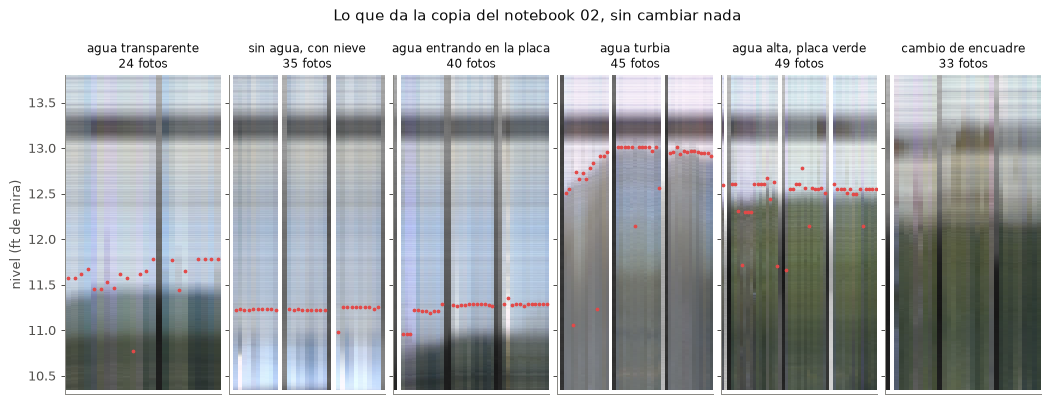

In [8]:
SALTO_CM = 3.0     # solo para contar saltos: el metodo no filtra nada


def marcar_saltos(serie):
    m = np.array([np.median(serie[max(i - 3, 0):i + 4]) for i in range(len(serie))])
    return np.abs(serie - m) > SALTO_CM


def medir_secciones():
    # recorre las fotos de las secciones, en paralelo, y marca los saltos dentro de cada bloque
    with ThreadPoolExecutor(8) as ex:
        d = pd.DataFrame(list(ex.map(medir_foto, fotos_s))).sort_values("hora").reset_index(drop=True)
    d["seccion"] = [seccion_de(a) for a in d.archivo]
    d["nivel_m"] = np.where(d.bajo_minimo, np.nan, d.nivel_bruto_cm / 100)
    d["salto"] = d.groupby("seccion").nivel_bruto_cm.transform(lambda s: marcar_saltos(s.values)).astype(bool)
    return d


def preparar_tiras(lista=None):
    # la mira de cada foto, enderezada con el tablero activo y en color: solo para dibujar
    def una(a):
        return a, T.enderezar(leer(a))
    with ThreadPoolExecutor(8) as ex:
        return dict(ex.map(una, fotos_s if lista is None else lista))


def dibujar_secciones(lecturas, tiras, titulo=None, alto=4.6, y0=10.3, y1=13.8):
    # un quimograma por seccion. lecturas: [(dataframe, color, tamano), ...]. tiras: {archivo: tira}
    fig, ax = plt.subplots(1, len(SECCIONES), figsize=(14, alto), sharey=True, gridspec_kw={"wspace": 0.05})
    for a, s in zip(ax, SECCIONES):
        lista = [x for x in fotos_s if seccion_de(x) == s]
        ps = [tiras[x][:, 8:ANCHO - 8].mean(1) for x in lista]     # los tableros de cada encuadre pueden tener distinto alto
        alto_k = max(len(p) for p in ps)
        K = np.stack([np.pad(p, ((0, alto_k - len(p)), (0, 0))) for p in ps], 1).astype(np.uint8)
        a.imshow(K[:, :, ::-1], extent=[0, K.shape[1], T.nivel_de(K.shape[0]) / PIE, T.nivel_sup / PIE], aspect="auto", interpolation="nearest")
        for d, color, ms in lecturas:
            ds = d.set_index("archivo").reindex(lista)
            a.plot(np.arange(len(lista)) + 0.5, ds.nivel_bruto_cm.where(~ds.bajo_minimo.astype(bool)) / PIE, ".", ms=ms, color=color)
        a.set_ylim(y0, y1); a.set_xticks([]); a.set_title("%s\n%d fotos" % (s, len(lista)), fontsize=9.5, color=TINTA)
    ax[0].set_ylabel("nivel (ft de mira)")
    if titulo:
        fig.suptitle(titulo, color=TINTA, y=1.04)


df_copia = medir_secciones()
df_copia.to_csv(os.path.join(SALIDAS, "03_v2_secciones.csv"), index=False, float_format="%.4f")
tiras_copia = preparar_tiras()
dibujar_secciones([(df_copia, ROJO, 4)], tiras_copia, "Lo que da la copia del notebook 02, sin cambiar nada")
df_copia.groupby("seccion", sort=False).agg(fotos=("archivo", "size"), sin_lectura=("nivel_bruto_cm", lambda s: int(s.isna().sum())), bajo_minimo=("bajo_minimo", "sum"),
                                            saltos=("salto", "sum"), parecido_seco=("parecido_seco", "median"), parecido_espejo=("parecido", "median"), dy_mediano=("dy", "median")).round(2)

## 1.9 Que cambio exactamente en esta copia

Se calcula leyendo el codigo de los dos notebooks, no a mano. Primero, los valores de configuracion, y luego que funciones son identicas, linea a linea, a la version final del notebook 02.

In [9]:
NB_02, NB_03 = os.path.join("..", "02_lago_china_primera_mejora", "02_lago_china_primera_mejora.ipynb"), "03_lago_owasco_segunda_mejora.ipynb"


def celdas_codigo(ruta):
    nb = json.load(open(ruta, encoding="utf-8"))
    return ["".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code"]


def definiciones(ruta):
    # funciones y clases de primer nivel, en orden: [(nombre, codigo), ...]
    salida = []
    for codigo in celdas_codigo(ruta):
        for nodo in ast.parse(codigo).body:
            if isinstance(nodo, (ast.FunctionDef, ast.ClassDef)):
                salida.append((nodo.name, "\n".join(codigo.splitlines()[nodo.lineno - 1:nodo.end_lineno])))
    return salida


def asignaciones(ruta):
    # primer valor escrito para cada nombre en una asignacion de primer nivel: {nombre: texto}
    salida = {}
    for codigo in celdas_codigo(ruta):
        for nodo in ast.parse(codigo).body:
            if isinstance(nodo, ast.Assign) and len(nodo.targets) == 1:
                obj, val = nodo.targets[0], nodo.value
                pares = zip(obj.elts, val.elts) if isinstance(obj, ast.Tuple) and isinstance(val, ast.Tuple) else [(obj, val)]
                for o, v in pares:
                    if isinstance(o, ast.Name):
                        salida.setdefault(o.id, ast.get_source_segment(codigo, v))
    return salida


defs_02, defs_03 = definiciones(NB_02), definiciones(NB_03)
a02, a03 = asignaciones(NB_02), asignaciones(NB_03)
CONFIGURACION = ["TEXTO_NIVEL", "BORDE_IZQ", "BORDE_DER", "NIVEL_SUP", "FILA_SUP", "NIVEL_INF", "FILA_INF", "PX_POR_CM", "ANCHO", "EXTRA_CM", "NIVEL_MINIMO", "NIVEL_MAX_AGUA", "NIVEL_MIN_BUSQUEDA",
                 "VENTANA_CM", "COLUMNAS", "FOTO_SECA", "BANDA_CM", "MARGEN_REGISTRO_CM", "PARECIDO_SECO_MIN"]
tabla_config = pd.DataFrame([{"valor": n, "China": a02.get(n, "-"), "Owasco": a03.get(n, "-"), "igual": a02.get(n) == a03.get(n)} for n in CONFIGURACION]).set_index("valor")
pd.set_option("display.max_colwidth", 80)
display(tabla_config)

ULTIMA_02, PRIMERA_03 = {}, {}
for n, f in defs_02:
    ULTIMA_02[n] = f
for n, f in defs_03:
    PRIMERA_03.setdefault(n, f)
METODO = ["leer", "rgb", "gris", "recta_por", "Tablero", "fila_homografia", "ncc", "ventanas", "curva_espejo", "espejo", "memorizar", "parecido_zona_seca", "parecido_con_seca",
          "a_01", "separacion", "elegir_fila", "registrar", "alinear", "medir_foto", "marcar_saltos", "medir_secciones"]
for n in METODO:
    print("%-20s %s" % (n, "identica a la version final del notebook 02" if ULTIMA_02[n] == PRIMERA_03[n] else "DISTINTA"))
    assert ULTIMA_02[n] == PRIMERA_03[n]
print("\nDistinta por el nombre de los archivos, no es del metodo:")
print("\n".join(l for l in difflib.unified_diff(ULTIMA_02["hora_de"].splitlines(), PRIMERA_03["hora_de"].splitlines(), "notebook 02", "esta copia", lineterm="", n=0)))

,China,Owasco,igual
valor,,,
TEXTO_NIVEL,"(0, 0, 0, 0)","(0, 0, 0, 0)",True
BORDE_IZQ,"[(2002, 1200), (1980, 1742)]","[(1106, 1800), (1154, 2250)]",False
BORDE_DER,"[(2056, 1200), (2033, 1742)]","[(1214, 1830), (1233, 2280)]",False
NIVEL_SUP,95.0,14.0 * PIE,False
FILA_SUP,1119.5,1562.0,False
NIVEL_INF,25.0,11.0 * PIE,False
FILA_INF,1762.0,2230.0,False
PX_POR_CM,9.0,6.0,False
ANCHO,54,90,False


leer                 identica a la version final del notebook 02
rgb                  identica a la version final del notebook 02
gris                 identica a la version final del notebook 02
recta_por            identica a la version final del notebook 02
Tablero              identica a la version final del notebook 02
fila_homografia      identica a la version final del notebook 02
ncc                  identica a la version final del notebook 02
ventanas             identica a la version final del notebook 02
curva_espejo         identica a la version final del notebook 02
espejo               identica a la version final del notebook 02
memorizar            identica a la version final del notebook 02
parecido_zona_seca   identica a la version final del notebook 02
parecido_con_seca    identica a la version final del notebook 02
a_01                 identica a la version final del notebook 02
separacion           identica a la version final del notebook 02
elegir_fila          iden

# 2. Datos iniciales: la v2, sin cambios, frente a la referencia

Aqui se abre la cota oficial del lago: USGS 04235396, cada 15 min, interpolada a la hora de cada foto. Las horas de las fotos y de la referencia estan en UTC. **Numeros de las secciones, no de la serie completa.**

Lo unico que se estima con ella es el cero: la cota esta en otro datum que la mira, asi que se suma **una sola constante**, la mediana de la diferencia en las fotos de las secciones con lectura. **No es una prueba a ciegas:** esta referencia ya se abrio con la version anterior de este notebook (30-oct-2026), y los puntos y marcas a mano venian de una configuracion hecha conociendola. Las fotos sin lectura o bajo el minimo no entran en el error, y se cuentan aparte.

Con referencia: 226 de 226 fotos de las secciones
Cero estimado con la referencia (secciones): 21341.22 cm (700.171 ft)


,,en la seccion,sin lectura,bajo el minimo,fotos,error abs. medio (cm),sesgo (cm),max abs. (cm),% en +-2 cm,% en +-5 cm
seccion,version,,,,,,,,,
agua transparente,"v2, su cero",24,1,2,21,5.76,2.97,22.56,19.05,57.14
"sin agua, con nieve","v2, su cero",35,6,0,29,22.16,22.16,24.27,0.00,0.00
agua entrando en la placa,"v2, su cero",40,6,0,34,17.28,17.28,22.66,0.00,0.00
agua turbia,"v2, su cero",45,6,0,39,5.64,-5.64,51.38,51.28,89.74
"agua alta, placa verde","v2, su cero",49,6,0,43,5.57,-5.26,29.69,25.58,76.74
cambio de encuadre,"v2, su cero",33,33,0,0,NaN,NaN,NaN,NaN,NaN
todas las secciones,"v2, su cero",226,58,2,166,10.91,5.10,51.38,21.08,48.19


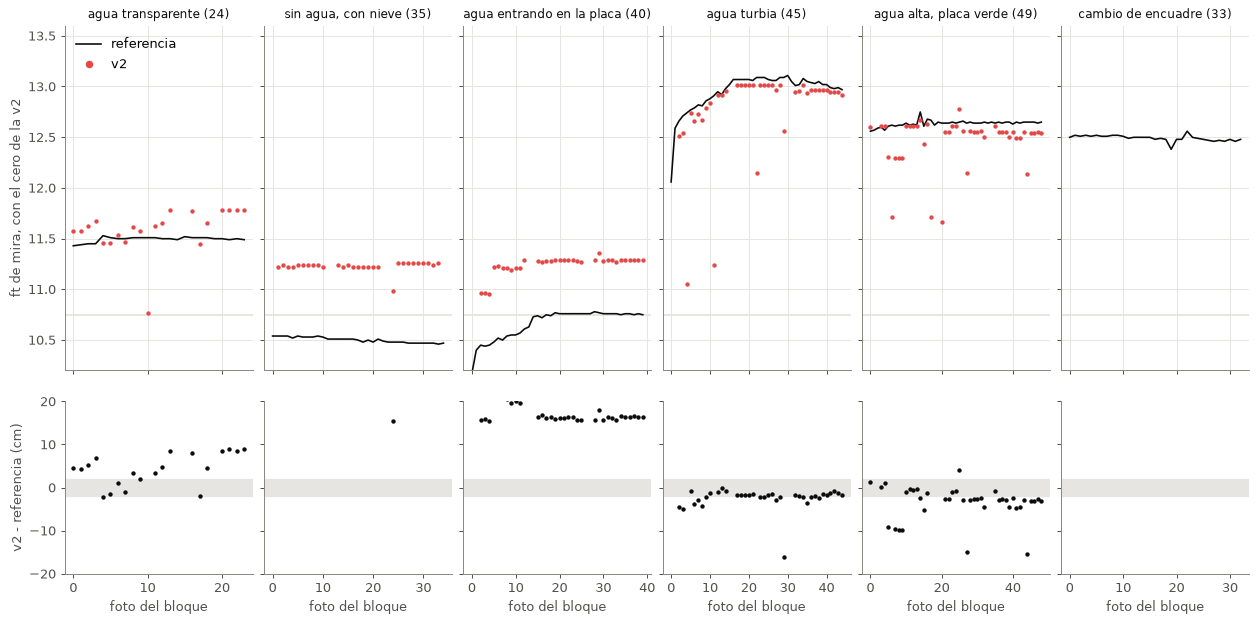

In [10]:
ref = pd.read_csv(CSV_REFERENCIA, parse_dates=["hora"]).dropna(subset=["cota_ngvd29"]).sort_values("hora").drop_duplicates("hora")
t_ref = ref.hora.astype("datetime64[ns]").astype("int64").values


def cota_cm(horas):
    t = pd.to_datetime(horas).astype("datetime64[ns]").astype("int64").values
    v = np.interp(t, t_ref, ref.cota_ngvd29.values) * PIE
    return np.where((t >= t_ref[0]) & (t <= t_ref[-1]), v, np.nan)


def resumen(e):
    e = e.dropna()
    return {"fotos": len(e), "error abs. medio (cm)": e.abs().mean(), "sesgo (cm)": e.mean(), "max abs. (cm)": e.abs().max(),
            "% en +-2 cm": 100 * (e.abs() <= 2).mean(), "% en +-5 cm": 100 * (e.abs() <= 5).mean()}


comp = df_copia.copy()
comp["ref_cm"] = cota_cm(comp.hora)
ok_v2 = comp.nivel_bruto_cm.notna() & ~comp.bajo_minimo.astype(bool) & comp.ref_cm.notna()
DATUM_V2 = float((comp.ref_cm - comp.nivel_bruto_cm)[ok_v2].median())
comp["ref_mira_cm"] = comp.ref_cm - DATUM_V2           # la referencia llevada a cm de mira con ese cero
comp["error_v2"] = (comp.nivel_bruto_cm + DATUM_V2 - comp.ref_cm).round(6)
print("Con referencia: %d de %d fotos de las secciones" % (comp.ref_cm.notna().sum(), len(comp)))
print("Cero estimado con la referencia (secciones): %.2f cm (%.3f ft)" % (DATUM_V2, DATUM_V2 / PIE))
filas_t = []
for s in list(SECCIONES) + ["todas las secciones"]:
    m_s = (comp.seccion == s) if s in SECCIONES else pd.Series(True, index=comp.index)
    filas_t.append({"seccion": s, "version": "v2, su cero", "en la seccion": int(m_s.sum()), "sin lectura": int((m_s & comp.nivel_bruto_cm.isna()).sum()),
                    "bajo el minimo": int((m_s & comp.bajo_minimo.astype(bool)).sum()), **resumen(comp.error_v2[ok_v2 & m_s])})
tabla_secciones = pd.DataFrame(filas_t).set_index(["seccion", "version"]).round(2)
tabla_secciones.to_csv(os.path.join(SALIDAS, "03_resultados_por_seccion.csv"))
comp.to_csv(os.path.join(SALIDAS, "03_v2_frente_a_referencia.csv"), index=False, float_format="%.4f")

fig, ax = plt.subplots(2, len(SECCIONES), figsize=(14, 7), sharey="row", sharex="col", gridspec_kw={"height_ratios": [2, 1], "wspace": 0.06})
for j, s in enumerate(SECCIONES):
    m_j = comp.seccion == s
    c = comp[m_j]
    x = np.arange(len(c))
    ok_j = ok_v2[m_j].values
    ax[0, j].axhline(NIVEL_MINIMO / PIE, color=REJILLA, lw=1.5, zorder=0)
    ax[0, j].plot(x, c.ref_mira_cm / PIE, "-", lw=1.3, color=TINTA, label="referencia")
    ax[0, j].plot(x[ok_j], c.nivel_bruto_cm[ok_j] / PIE, "o", ms=2.5, color=ROJO, label="v2")
    ax[0, j].set_title("%s (%d)" % (s, len(c)), fontsize=9.5, color=TINTA); ax[0, j].grid(color=REJILLA, lw=0.8); ax[0, j].set_axisbelow(True)
    ax[1, j].axhspan(-2, 2, color=REJILLA, zorder=0); ax[1, j].plot(x[ok_j], c.error_v2[ok_j], "o", ms=2.5, color=TINTA)
    ax[1, j].set_ylim(-20, 20); ax[1, j].set_xlabel("foto del bloque")
ax[0, 0].set_ylabel("ft de mira, con el cero de la v2"); ax[1, 0].set_ylabel("v2 - referencia (cm)"); ax[0, 0].legend(frameon=False, markerscale=2, loc="upper left")
ax[0, 0].set_ylim(10.2, 13.6)
fig.subplots_adjust(left=0.05, right=0.99, top=0.95, bottom=0.08, hspace=0.12)
plt.savefig(os.path.join(SALIDAS, "03_nivel.png"), dpi=130, facecolor="white")
tabla_secciones

**Lectura de la tabla, tal cual, sin reajustar nada.**

- **Con agua sobre la placa la v2 sigue el agua, con poca precision:** 5.6 a 5.8 cm de error medio por seccion, con sesgos de signo contrario segun la seccion (de -5.6 a +3.0 cm). El espejo arrastra la lectura (parte 3) y la regla esta torcida (1.5).
- **Con el agua bajo la placa o en su pie, ninguna foto queda bajo el minimo:** la lectura cae sobre la placa, en promedio 17 a 22 cm por encima del agua. Parte de ese error viene de la regla torcida y del cero, que se calcula tambien con estas lecturas.
- **Dos fotos con agua transparente quedan bajo el minimo por error:** el agua estaba en 11.5 ft, sobre la placa.
- **Tras el cambio de encuadre no hay ninguna lectura:** la camara se movio mas de lo que cubre el registro y la parte que nunca se moja no se reconoce (parecido mediano 0.08, en 1.8).
- **25 fotos oscuras, del amanecer y el anochecer, quedan sin lectura**, como debe ser.
- **No hay que fiarse del cero:** 700.171 ft, calculado tambien con las lecturas falsas.

# 3. Problemas

Se buscan con las marcas de control, mirando las fotos y midiendo cada pista por separado. **Solo se anotan los que pueden aparecer en cualquier sitio parecido.** La referencia ya esta abierta (parte 2), asi que este diagnostico no es a ciegas; la regla torcida se ve sin ella, con las marcas de control (1.5).

## 3.1 Cada pista por separado

En la misma foto alineada se toma la fila que elige la suma (la v2), la que elige la separacion sola y la que elige el espejo solo. Cada una con su propio cero, como la v2. Es solo un diagnostico: no cambia el metodo.

In [11]:
def tres_pistas(archivo):
    # fila elegida por la suma (la v2), por la separacion sola y por el espejo solo, en la misma foto alineada
    R0 = T.enderezar(gris(leer(archivo)))
    dx, dy, seco = registrar(R0)
    R = alinear(R0, dx, dy)
    _, _, filas, curva = espejo(R)
    sep = separacion(R, filas)
    suma = a_01(sep) + a_01(curva)
    return {"archivo": archivo, "suma": T.nivel_de(filas[np.argmax(suma)]), "separacion": T.nivel_de(filas[np.argmax(sep)]),
            "espejo": T.nivel_de(filas[np.argmax(curva)]), "seco": seco}


with ThreadPoolExecutor(8) as ex:
    pistas = comp.merge(pd.DataFrame(list(ex.map(tres_pistas, comp.archivo))), on="archivo")
filas_p = []
for pista in ("suma", "separacion", "espejo"):
    v = pistas[pista]
    ok_p = (pistas.seco >= PARECIDO_SECO_MIN) & pistas.ref_cm.notna() & (v >= NIVEL_MINIMO)
    cero_p = float((pistas.ref_cm - v)[ok_p].median())          # cada pista con su propio cero
    e_p = (v + cero_p - pistas.ref_cm).round(6)
    for s in list(SECCIONES) + ["todas las secciones"]:
        m_s = ok_p & (pistas.seccion == s) if s in SECCIONES else ok_p
        filas_p.append({"seccion": s, "pista": pista, **resumen(e_p[m_s])})
tabla_pistas = pd.DataFrame(filas_p).set_index(["seccion", "pista"]).round(2)
tabla_pistas.to_csv(os.path.join(SALIDAS, "03_pistas_por_seccion.csv"))
print("La suma coincide con la v2 en todas las fotos:", bool(np.allclose(pistas.suma[pistas.seco >= PARECIDO_SECO_MIN],
                                                                          pistas.nivel_bruto_cm[pistas.seco >= PARECIDO_SECO_MIN])))
tabla_pistas[["fotos", "error abs. medio (cm)", "% en +-5 cm"]].unstack("pista")

La suma coincide con la v2 en todas las fotos: True


fotos                 error abs. medio (cm)  \
pista                     espejo separacion suma                espejo   
seccion                                                                  
agua alta, placa verde        43         43   43                 38.52   
agua entrando en la placa     34         34   34                 14.12   
agua transparente             22         18   21                  5.24   
agua turbia                   32         39   39                 51.81   
cambio de encuadre             0          0    0                   NaN   
sin agua, con nieve           29         29   29                 18.55   
todas las secciones          160        163  166                 27.80   

                                            % en +-5 cm                    
pista                     separacion   suma      espejo separacion   suma  
seccion                                                                    
agua alta, placa verde          2.71   5.57        0.00     100.00  76.74  
agua entrando en la placa      11.04  17.28        0.00       0.00   0.00  
agua transparente               5.87   5.76       81.82      77.78  57.14  
agua turbia                     1.42   5.64        0.00     100.00  89.74  
cambio de encuadre               NaN    NaN         NaN        NaN    NaN  
sin agua, con nieve            15.97  22.16        0.00       0.00   0.00  
todas las secciones             6.85  10.91       11.25      58.90  48.19

## 3.2 Las fotos

En cada tira, la regla enderezada como en la copia, con lados paralelos (por eso las rayas salen inclinadas); la linea roja es lo que lee la v2 y la cian discontinua, la referencia llevada a la regla con el cero de la parte 2.

Con el agua bajo la placa o en su pie: lee de 10.95 a 11.36 ft; la referencia va de 10.44 a 10.78 ft


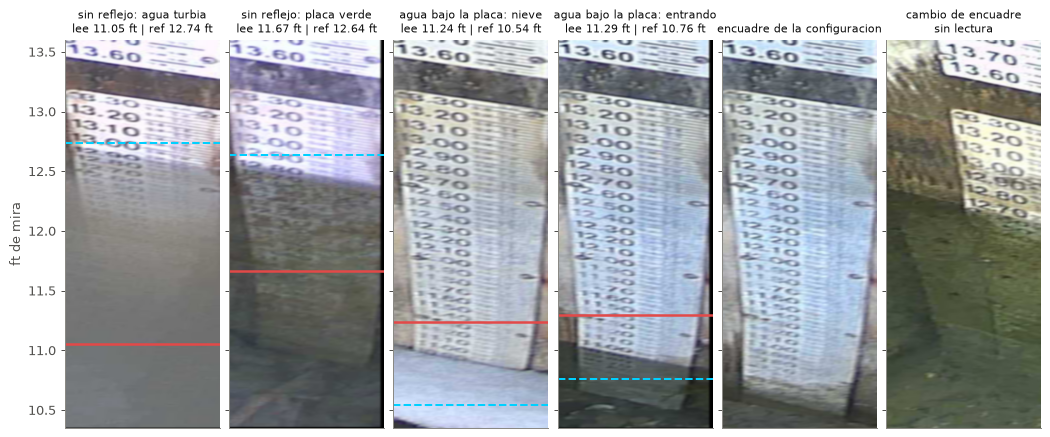

In [12]:
EJEMPLOS = [("sin reflejo: agua turbia", "2026-04-01T13-00"), ("sin reflejo: placa verde", "2026-05-14T10-00"),
            ("agua bajo la placa: nieve", "2026-01-22T17-00"), ("agua bajo la placa: entrando", "2026-03-09T20-00"),
            ("encuadre de la configuracion", None), ("cambio de encuadre", "2026-09-13T16-00")]
fig, ax = plt.subplots(1, len(EJEMPLOS), figsize=(14, 5.6), sharey=True, gridspec_kw={"wspace": 0.06})
for a, (titulo, pref) in zip(ax, EJEMPLOS):
    if pref is None:
        archivo, fila = FOTO_SECA, None
    else:
        fila = comp[comp.archivo.str.split("___").str[1].str.startswith(pref)].iloc[0]
        archivo = fila.archivo
    img = leer(archivo)
    color = T.enderezar(img)
    if fila is not None and np.isfinite(fila.nivel_bruto_cm):
        dx_e, dy_e, _ = registrar(T.enderezar(gris(img)))
        color = alinear(color, dx_e, dy_e)
    a.imshow(rgb(color), extent=[0, ANCHO, T.nivel_de(T.tam[1]) / PIE, T.nivel_sup / PIE], aspect="auto", interpolation="bicubic")
    if fila is not None and np.isfinite(fila.nivel_bruto_cm):
        a.axhline(fila.nivel_bruto_cm / PIE, color=ROJO, lw=2)
        a.axhline(fila.ref_mira_cm / PIE, color="#00d0ff", lw=1.6, ls="--")
    texto = "" if fila is None else ("\nlee %.2f ft | ref %.2f ft" % (fila.nivel_bruto_cm / PIE, fila.ref_mira_cm / PIE) if np.isfinite(fila.nivel_bruto_cm) else "\nsin lectura")
    a.set_title(titulo + texto, fontsize=9, color=TINTA); a.set_xticks([])
ax[0].set_ylim(10.35, 13.6); ax[0].set_ylabel("ft de mira")
bajo = comp[comp.seccion.isin(["sin agua, con nieve", "agua entrando en la placa"]) & comp.nivel_bruto_cm.notna()]
print("Con el agua bajo la placa o en su pie: lee de %.2f a %.2f ft; la referencia va de %.2f a %.2f ft" % (
    bajo.nivel_bruto_cm.min() / PIE, bajo.nivel_bruto_cm.max() / PIE, bajo.ref_mira_cm.min() / PIE, bajo.ref_mira_cm.max() / PIE))

## 3.3 Los problemas que sirven para otros sitios

1. **La regla vista en perspectiva sale torcida.** El tablero con lados paralelos supone que la camara ve la regla de frente. Esta la ve de lado y desde arriba: las rayas salen inclinadas unos 20 grados y la escala cambia con la altura, asi que las marcas de control quedan corridas de -9.7 a +8.3 cm (1.5), y cada lectura con ellas, segun la altura del agua. Se ve sin la referencia.
2. **Sin reflejo, el espejo estorba.** El agua de este lago es transparente y no refleja la mira: el espejo no tiene que encontrar y se engancha en las rayas de la mira, que son muy regulares. Como pesa lo mismo que la separacion, arrastra la suma: con agua turbia y con la placa verde, la separacion sola da 1.42 y 2.71 cm, el espejo solo 51.81 y 38.52 cm, y la suma 5.64 y 5.57 cm (tabla 3.1). Con agua transparente las dos pistas quedan parecidas (5.87 y 5.24 cm).
3. **Con el agua bajo la mira, no lo puede decir.** La suma siempre elige una fila dentro del rango, y el rango solo baja 0.1 ft por debajo del pie de la placa: con el agua bajo la placa o en su pie, ninguna foto de esas dos secciones queda bajo el minimo y la lectura cae sobre la placa (parte 2).
4. **Si la camara cambia de encuadre, deja de medir.** La parte que nunca se moja ya no se reconoce (parte 2) y todas las fotos quedan sin lectura. Evita numeros falsos, pero no vuelve a medir hasta que se configure de nuevo.

**Lo que no dio problema:** las algas y el agua turbia no impiden medir con la separacion, y las fotos oscuras del amanecer y el anochecer quedan sin lectura, como debe ser.

# 4. Cambios al codigo

## Cambios respecto a la version anterior

| # | Que cambia | Por que (problema) | Seccion |
|---|---|---|---|
| 1 | **La regla en perspectiva.** Se endereza con una perspectiva ajustada con los bordes y todos los niveles leidos a mano; la inclinacion de las rayas la mide el programa | con lados paralelos, la regla vista de lado sale torcida (3.3, problema 1) | 4.1 |
| 2 | **Zona de la separacion.** La separacion elige la zona; la suma de las dos pistas solo elige la fila dentro de 2 franjas (4 cm) de ese corte | sin reflejo, el espejo arrastraba la suma lejos del agua (3.3, problema 2) | 4.2 |
| 3 | **Varios encuadres.** Una camara puede tener varios encuadres; uno nuevo se configura solo con su foto seca, trasladando la calibracion del original, y en cada foto se usa el que mejor reconoce la guia | tras el cambio de encuadre no habia ninguna lectura (3.3, problema 4) | 4.3 |

**Requisito: los mismos valores en todas las camaras.** El valor nuevo del metodo es `ZONA_FRANJAS = 2`. Se fijo mirando los tres sitios con sus referencias ya abiertas: con 1 franja Meguro empeora, y entre 2 y 3 franjas el resultado cambia poco. **No es a ciegas** (parte 7). La perspectiva no agrega valores del metodo: usa los niveles leidos a mano en cada camara (`NIVELES_A_MANO`), que ya existian como marcas de control. `ZONA_RASGOS` solo dice donde buscar la regla en una foto nueva, relativo al tablero. Los encuadres 2 y 3 de Owasco solo necesitan su foto seca y su minimo, que se leyo a ojo antes de esta prueba conociendo la referencia.

**Sin resolver:** con el agua bajo la mira, el metodo sigue sin poder decirlo (parte 7).

## 4.1 Cambio 1: la regla en perspectiva

**El problema.** El tablero con lados paralelos supone que la mira se ve de frente. Esta camara la ve de lado y desde arriba: las rayas salen inclinadas unos 20 grados y la escala cambia con la altura, asi que las marcas de control quedan corridas 6 a 10 cm (1.5 y 3.3).

**Que se cambia.** La regla se endereza con una perspectiva (homografia) ajustada por minimos cuadrados con todo lo que se lee a mano: los dos puntos de cada borde van a la primera y a la ultima columna, y **cada nivel leido** (los dos de siempre y las marcas de control) va a su fila. Para cada nivel basta un punto: la inclinacion de sus rayas la mide el programa en la foto, buscando la que deja mas nitido el perfil de filas. Si un nivel se marco con dos puntos sobre su raya, se usan esos. `Tablero` pasa a recibir la perspectiva ya calculada. Con una camara de frente esto da casi lo mismo que los lados paralelos; con una camara de lado, no. Como las marcas de control entran en el ajuste, se comprueban dejando cada una fuera.

**Lo que da este cambio solo.** Al final se mide la v2 con la regla en perspectiva y nada mas cambiado; se compara con la referencia en la parte 5.

Inclinacion medida de las rayas: {'14.0 ft': '19.5 grados', '11.0 ft': '23.4 grados', '14.4 ft': '16.4 grados', '13.6 ft': '21.2 grados', '13.2 ft': '21.1 grados', '12.5 ft': '23.0 grados', '11.8 ft': '21.8 grados'}


Marcas de control, medido - real (cm). Con la perspectiva, cada una se predice con un ajuste hecho sin ella.


,"v2, lados paralelos","perspectiva, ajustada sin esa marca"
marca (ft),,
11.8,-7.00,-0.34
12.5,-9.72,-0.35
13.2,-7.51,0.55
13.6,-6.01,0.28
14.4,8.34,0.25


,fotos,sin_lectura,bajo_minimo,saltos,parecido_seco,dy_mediano
seccion,,,,,,
agua transparente,24,0,0,6,0.96,0.0
"sin agua, con nieve",35,3,0,3,0.98,0.0
agua entrando en la placa,40,1,0,9,0.97,0.0
agua turbia,45,6,0,3,0.91,1.0
"agua alta, placa verde",49,3,0,5,0.93,1.0
cambio de encuadre,33,33,0,0,0.43,14.0


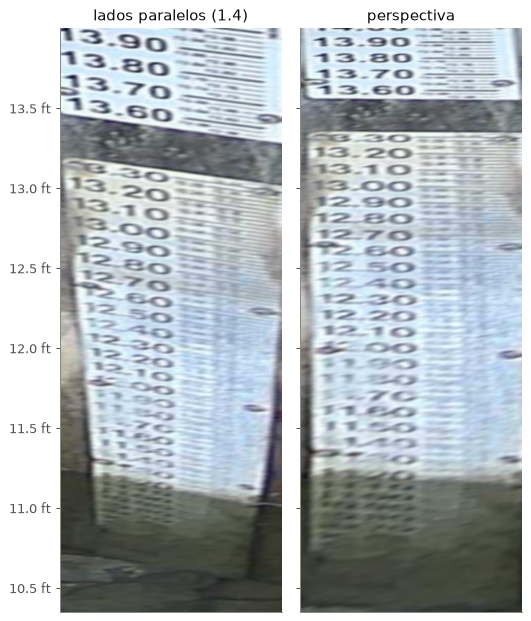

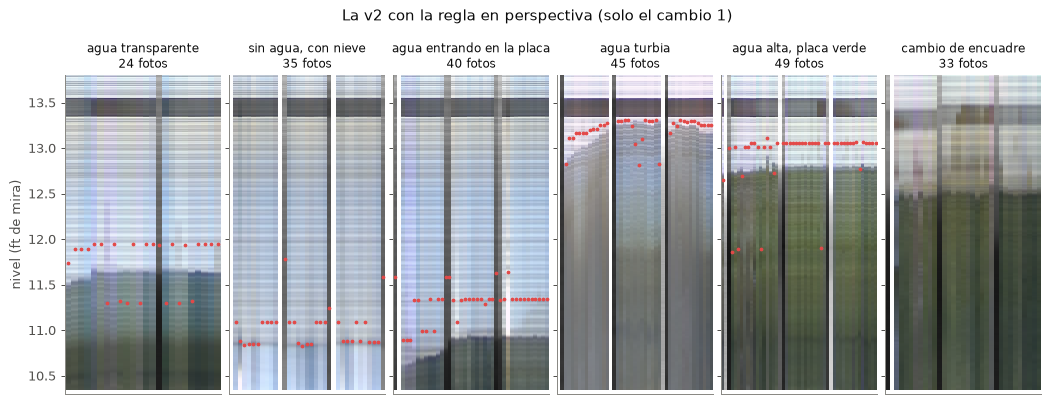

In [13]:
def pendiente_rayas(G, x_i, x_d, fila, alto=30, smax=0.7, n=561):
    # [v3] inclinacion de las rayas cerca de una fila de la foto (filas por columna): la que deja mas nitido el perfil de filas
    x0, x1 = float(x_i(fila)), float(x_d(fila))
    xs = np.arange(int(x0 + 0.12 * (x1 - x0)), int(x1 - 0.12 * (x1 - x0)) + 1).astype(np.float32)
    xc = (x0 + x1) / 2
    ys = np.arange(fila - alto, fila + alto + 1, dtype=np.float32)
    mejor, s_mejor = -1, 0.0
    for s in np.linspace(-smax, smax, n):
        mapy = (ys[:, None] + s * (xs[None, :] - xc)).astype(np.float32)
        mapx = np.ascontiguousarray(np.broadcast_to(xs[None, :], mapy.shape))
        perfil = cv2.remap(G, mapx, mapy, cv2.INTER_LINEAR).mean(1)
        nitidez = float(np.var(np.diff(perfil)))
        if nitidez > mejor:
            mejor, s_mejor = nitidez, float(s)
    return s_mejor


def ajustar_perspectiva(G, borde_izq, borde_der, niveles, nivel_sup, px_por_cm, ancho_px):
    # [v3] perspectiva foto -> tablero por minimos cuadrados: los bordes van a la columna 0 y a la ultima, y cada nivel a su fila.
    # Un nivel es un punto (x, fila) de su raya, con x = None para el centro de la placa, y la inclinacion se mide en la foto;
    # o una lista de dos puntos sobre la raya, marcados a mano
    x_i, x_d = recta_por(borde_izq), recta_por(borde_der)
    A, b = [], []
    for (x, y), u in [(p, 0.0) for p in borde_izq] + [(p, float(ancho_px)) for p in borde_der]:
        A.append([x, y, 1, 0, 0, 0, -u * x, -u * y]); b.append(u)
    for nivel, p in niveles.items():
        if isinstance(p, list):
            puntos = p
        else:
            x, f = p
            x0, x1 = float(x_i(f)), float(x_d(f))
            x = (x0 + x1) / 2 if x is None else x
            s, d = pendiente_rayas(G, x_i, x_d, f), 0.3 * (x1 - x0)
            puntos = [(x - d, f - s * d), (x + d, f + s * d)]
        v = (nivel_sup - nivel) * px_por_cm
        for x, y in puntos:
            A.append([0, 0, 0, x, y, 1, -v * x, -v * y]); b.append(v)
    h = np.linalg.lstsq(np.float64(A), np.float64(b), rcond=None)[0]
    return np.append(h, 1.0).reshape(3, 3)


class Tablero:
    # [v3] la perspectiva M (foto -> tablero) y los niveles de arriba y de abajo: cada fila es un nivel fijo
    def __init__(self, M, nivel_sup, nivel_inf, px_por_cm, ancho_px, extra_cm):
        self.nivel_sup, self.px_por_cm = float(nivel_sup), float(px_por_cm)
        alto = (nivel_sup - nivel_inf) * px_por_cm
        self.M, self.M_inv = M, np.linalg.inv(M)                    # [v3]
        self.tam = (int(ancho_px), int(alto + extra_cm * px_por_cm))

    def enderezar(self, img):
        return cv2.warpPerspective(img, self.M, self.tam, flags=cv2.INTER_LINEAR)   # [v3]

    def fila_de(self, nivel):
        return (self.nivel_sup - nivel) * self.px_por_cm

    def nivel_de(self, fila):
        return self.nivel_sup - fila / self.px_por_cm

    def a_tablero(self, x, y):
        return cv2.perspectiveTransform(np.float64([[[x, y]]]), self.M)[0, 0]       # [v3] punto de la foto -> (columna, fila) del tablero

    def a_foto(self, col, fila):
        return cv2.perspectiveTransform(np.float64([[[col, fila]]]), self.M_inv)[0, 0]   # [v3] punto del tablero -> (x, y) de la foto


# >>> AJUSTABLE <<< [v3] todos los niveles leidos a mano en la foto de agua mas baja: los dos de siempre (x = None: centro de la placa) y las marcas de control
NIVELES_A_MANO = {NIVEL_SUP: (None, FILA_SUP), NIVEL_INF: (None, FILA_INF), **{c * PIE: (x, f) for c, (x, f) in MARCAS_CONTROL.items()}}
G_config = gris(leer("NY_Owasco_Lake_near_Auburn_Staff___2025-12-23T17-00-06Z.jpg"))     # la foto donde se leyo todo (1.3)
T = Tablero(ajustar_perspectiva(G_config, BORDE_IZQ, BORDE_DER, NIVELES_A_MANO, NIVEL_SUP, PX_POR_CM, ANCHO), NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
print("Inclinacion medida de las rayas:", {"%.1f ft" % (k / PIE): "%.1f grados" % np.degrees(np.arctan(pendiente_rayas(G_config, x_izq, x_der, f)))
                                          for k, (x, f) in NIVELES_A_MANO.items()})

filas_v = []
for c, (x, f) in sorted(MARCAS_CONTROL.items()):
    sin_ella = {k: v for k, v in NIVELES_A_MANO.items() if k != c * PIE}
    Tk = Tablero(ajustar_perspectiva(G_config, BORDE_IZQ, BORDE_DER, sin_ella, NIVEL_SUP, PX_POR_CM, ANCHO), NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
    filas_v.append({"marca (ft)": c, "v2, lados paralelos": float(tabla_marcas.loc[c].iloc[0]), "perspectiva, ajustada sin esa marca": Tk.nivel_de(Tk.a_tablero(x, f)[1]) - c * PIE})
tabla_marcas_v3 = pd.DataFrame(filas_v).set_index("marca (ft)").round(2)
fig, ax = plt.subplots(1, 2, figsize=(6, 7), sharey=True)
for a, im, titulo in [(ax[0], tablero, "lados paralelos (1.4)"), (ax[1], T.enderezar(leer(FOTO)), "perspectiva")]:
    a.imshow(rgb(im), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
    a.set_xticks([]); a.set_title(titulo, color=TINTA)
ax[0].set_yticks([T.fila_de(c * PIE) for c in niveles]); ax[0].set_yticklabels(["%.1f ft" % c for c in niveles])
plt.tight_layout()
print("Marcas de control, medido - real (cm). Con la perspectiva, cada una se predice con un ajuste hecho sin ella.")
display(tabla_marcas_v3)

# Lo que da este cambio solo: la v2, con la regla en perspectiva y nada mas cambiado
memorizar()                                        # la mira seca, enderezada con la perspectiva
df_persp = medir_secciones()
df_persp.to_csv(os.path.join(SALIDAS, "03_v2_perspectiva_secciones.csv"), index=False, float_format="%.4f")
tiras_persp = preparar_tiras()
dibujar_secciones([(df_persp, ROJO, 4)], tiras_persp, "La v2 con la regla en perspectiva (solo el cambio 1)")
df_persp.groupby("seccion", sort=False).agg(fotos=("archivo", "size"), sin_lectura=("nivel_bruto_cm", lambda s: int(s.isna().sum())), bajo_minimo=("bajo_minimo", "sum"),
                                            saltos=("salto", "sum"), parecido_seco=("parecido_seco", "median"), dy_mediano=("dy", "median")).round(2)